# Second-Order Unit Search on Asteroids RAM

> **Overview.** `03_unit_search.ipynb`'s method with three changes that let it find the nonlinear features it misses on
> the full RAM: second-order probes on each output choose a new LTU's parent output and inputs, and young LTUs are
> protected from search.

**Setup.** The data and scores of `03_unit_search.ipynb` (mode 0, difficulty 0, learned once in time order), with one
hidden layer of 600 LTUs, step-sizes capped at 0.1 and the outputs' step-sizes on the LTUs at 1e-3 (03's learner blows up
on this data without them). The changes:
1. **Probes.** Each output keeps two unit vectors that follow, by Oja's rule on its error e, the most positive and most
   negative eigenvectors of its error-weighted input covariance E[e x xᵀ] (diagonal removed). An XOR-like dependence shows
   up there even though each input alone is uncorrelated with the error.
2. **Parents and inputs.** A new LTU's parent is an output drawn in proportion to its larger probe's estimated loss
   reduction, cov(e, q)² / var(q), with q the probe's quadratic feature; it reads the top 15 inputs of each of its
   parent's probes.
3. **Maturity.** LTUs younger than 50k steps are not replaced by search, and the LTUs are added at step 20k, once the
   probes have formed.

Baseline: the same learner without the changes. 3 seeds.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [ ]:
# --- Data (as in 02_world_model.ipynb) ---
DATA_FILE = 'data_mode0_diff0.npz'
N_STEPS = 200_000                      # transitions learned from, in order
LOG_EVERY = N_STEPS // 100           # steps per plotted average
N_ACTIONS = 14
N_INPUTS, N_OUTPUTS = 1024 + N_ACTIONS, 1024    # RAM bits and the one-hot action in, next-RAM bits out

# --- Learner (as in unit_search/step_by_step/6_sparse_target_network.ipynb) ---
N_DEPTHS = 1                         # hidden layers
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the inputs and hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
STEP_CAP, LTU_STEP_CAP = 0.1, 1e-3   # largest step-size; largest step-size of the outputs' weights on the LTUs
WIDTH = 600                          # hidden LTUs per depth
FAN_IN = 30                          # a new LTU first reads this many sources
REPLACED_SHARE = 1 / 8               # share of the LTUs replaced at each search step, the weakest
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FLAT_SHARE = 0.1                     # an LTU with less than this share of its input |weights| on the layer below
                                     # acts as an LTU of that layer
WINDOW = 1_000                       # steps between growth steps
PERIOD = 10_000                      # steps between search steps
N_SEEDS = 3

# --- The changes ---
PROBE_RATE = 1e-4                    # Oja step-size of the probes
PROBE_INPUTS = 15                    # a new LTU reads this many top inputs of each of its parent's probes
MATURITY = 50_000                    # LTUs younger than this many steps are not replaced
ADD_STEP = 20_000                    # step at which the LTUs are added

data = np.load(DATA_FILE)
valid = data['valid']
ram, action, next_ram = (data['ram'][:-1][valid][:N_STEPS], data['action'][valid][:N_STEPS],
                         data['ram'][1:][valid][:N_STEPS])
DATA = tuple(jnp.asarray(v) for v in (ram, action, next_ram))

# Bytes counted in the accuracy, as in Veličković et al. 2021: those whose next value has entropy above 0.6 nats.
p = np.stack([np.bincount(byte, minlength=256) for byte in next_ram.T]) / len(next_ram)
VARIED = -(p * np.log(np.where(p > 0, p, 1))).sum(1) > 0.6
RMR_ACCURACY = 0.8069  # Veličković et al. 2021, Table 2, Asteroids, message-passing network

# Reference: copy the current RAM. For the loss, each bit keeps its value with probability 1 - q, where q is the
# fraction of bits that change. Both over the last 10% of steps.
last = slice(-N_STEPS // 10, None)
q = (np.unpackbits(ram[last], axis=1) != np.unpackbits(next_ram[last], axis=1)).mean()
copy_final = [-(q * np.log(q) + (1 - q) * np.log(1 - q)), (ram[last][:, VARIED] == next_ram[last][:, VARIED]).mean()]

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped like the hidden units.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


def set_width(width):
    # Sizes the learner: `width` hidden units per depth (PER_DEPTH), N_LTUS in all, of which search replaces REPLACED;
    # each hidden unit's depth (SLOT_DEPTH); the hidden units of each depth (DEPTHS); and LOWER[u, j], whether hidden
    # unit u may read source j of [inputs, hidden units, 1]: every input and the bias, and the hidden units of lower
    # depth.
    global PER_DEPTH, N_LTUS, REPLACED, SLOT_DEPTH, DEPTHS, LOWER
    PER_DEPTH, N_LTUS = width, N_DEPTHS * width
    REPLACED = round(REPLACED_SHARE * N_LTUS)
    SLOT_DEPTH = jnp.arange(N_LTUS) // PER_DEPTH + 1
    DEPTHS = [slice(d * PER_DEPTH, (d + 1) * PER_DEPTH) for d in range(N_DEPTHS)]
    LOWER = (jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool)
             .at[:, N_INPUTS:-1].set(SLOT_DEPTH[None] < SLOT_DEPTH[:, None]))


set_width(WIDTH)


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, hidden units, 1 (the bias)], of which they read those in
    # `reads`; w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says
    # which of the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden unit's shadow weight on an output, and
    shadow_hidden: jax.Array    # (N_LTUS, N_LTUS) on a higher hidden unit (rows): +-1 on one output or unit, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each unit's last new connection
    input_mean: jax.Array       # (N_INPUTS,): running mean of each input bit
    probes: jax.Array           # (2, N_OUTPUTS, N_INPUTS): each output's ascent and descent probe, unit vectors
    probe_eq: jax.Array         # (2, N_OUTPUTS): running means of e q, q and q^2, q = (probe . x)^2 minus its
    probe_q: jax.Array          # diagonal part, the probe's quadratic feature
    probe_q2: jax.Array
    error_mean: jax.Array       # (N_OUTPUTS,): running mean of each output's error
    age: jax.Array              # (N_LTUS,): steps since each slot's unit was wired
    use_probes: jax.Array       # whether new LTUs' parents and inputs come from the probes
    maturity: jax.Array         # LTUs younger than this are not replaced


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0) | jnp.any(net.shadow_hidden != 0, 0)


def probe_gain(net):
    # Each output's larger estimated loss reduction from adding a probe's quadratic feature: cov(e, q)^2 / var(q).
    cov = net.probe_eq - net.error_mean[None] * net.probe_q
    return (cov ** 2 / jnp.maximum(net.probe_q2 - net.probe_q ** 2, 1e-8)).max(0)


def probe_inputs(net):
    # Shaped like w['hidden']: 1 on the top PROBE_INPUTS inputs (by |loading|) of each probe of each unit's parent.
    u = jnp.abs(net.probes[:, jnp.argmax(jnp.abs(net.shadow), 0)])
    top = jax.lax.top_k(u, PROBE_INPUTS)[1].transpose(1, 0, 2).reshape(N_LTUS, -1)
    return jnp.zeros((N_LTUS, N_INPUTS + N_LTUS + 1)).at[jnp.arange(N_LTUS)[:, None], top].set(1.0)


def parent_weights(net):
    # Shaped like w['hidden']: each hidden unit's shadow weight times its parent's weights on the sources it may
    # read (an output's weight on an input is the linear learner's), 0 elsewhere and on the bias.
    targets = net.shadow.T @ net.w['output'] + net.shadow_hidden.T @ (net.w['hidden'] * net.reads)
    return targets.at[:, -1].set(0.0) * LOWER


def usefulness(net):
    # Each hidden unit's sum of |outgoing weights|, to the outputs and to higher hidden units.
    return (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
            + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))


def init_net(units, use_probes=False, maturity=0):
    # `units` hidden units (the rest of the N_LTUS slots left empty), with shadow weights +1 and -1 alternately on the
    # first output (redrawn, and the units wired, when they are added); every weight 0, the outputs reading every input
    # and the bias (the linear learner), and the inputs' running means at 0.5; random probes, and use_probes and
    # maturity as given.
    slot = jnp.arange(N_LTUS)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = jnp.zeros((N_OUTPUTS, N_LTUS)).at[0].set(sign)
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + N_LTUS + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, jnp.zeros(w['hidden'].shape, bool), mask, OPTIMIZER.init(w), stats, shadow,
               jnp.zeros((N_LTUS, N_LTUS)), jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)), jnp.full(N_INPUTS, 0.5), PROBE_INIT,
               *jnp.zeros((3, 2, N_OUTPUTS)), jnp.zeros(N_OUTPUTS), jnp.zeros(N_LTUS, jnp.int32), use_probes, maturity)


PROBE_INIT = jax.random.normal(jax.random.PRNGKey(0), (2, N_OUTPUTS, N_INPUTS))
PROBE_INIT = PROBE_INIT / jnp.linalg.norm(PROBE_INIT, axis=-1, keepdims=True)


def redraw(net, key, replaced):
    # The `replaced` hidden units' new shadow weights, +1 or -1 by slot, each on a unit of a higher layer, their parent:
    # a layer drawn uniformly among those above the unit's depth, the outputs (layer N_DEPTHS + 1) included, then a
    # unit of it at random (an output in proportion to its probe gain, if use_probes).
    layer_key, unit_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    layer = jax.random.randint(layer_key, (N_LTUS,), SLOT_DEPTH + 1, N_DEPTHS + 2)
    on_output = layer > N_DEPTHS
    index = jax.random.randint(unit_key, (N_LTUS,), 0, jnp.where(on_output, N_OUTPUTS, PER_DEPTH))
    by_gain = jax.random.categorical(unit_key, jnp.log(jnp.maximum(probe_gain(net), 1e-12)), shape=(N_LTUS,))
    index = jnp.where(net.use_probes & on_output, by_gain, index)
    sign = jnp.where(slot % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == index) * jnp.where(on_output, sign, 0.0)
    shadow_hidden = (slot[:, None] == (layer - 1) * PER_DEPTH + index) * jnp.where(on_output, 0.0, sign)
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow),
                        shadow_hidden=jnp.where(replaced, shadow_hidden, net.shadow_hidden))


def rewire(net, key, replaced, rows, random):
    # The `rows` hidden units (a mask over slots, among the `replaced` units) each read FAN_IN sources (no more than
    # their parent has nonzero weights on) and the bias, the sources, inputs and lower-depth units alike, drawn without
    # replacement with probability proportional to the square of their parent's weight on them (uniformly among the
    # sources they may read, if random; the top inputs of their parent's probes, if use_probes) (Gumbel top-k), with fresh LeCun uniform weights over their fan-in, output
    # weights at 0, and fresh statistics, Autostep state and gradient sums; the other units' connections from the
    # replaced units are cut. Then every unit reads the units with shadow weights on it, connections it lacks starting
    # at weight 0 with step-size FAST_STEP_SIZE.
    draw_key, w_key = jax.random.split(key)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced units
    seeds = jnp.where(net.use_probes, probe_inputs(net), parent_weights(net))
    weights = jnp.where(cut, 0.0, jnp.where(random, LOWER, seeds))[:, :-1]
    fan_in = jnp.minimum(FAN_IN, (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    changed = rows[:, None] | cut
    reads = jnp.where(changed, reads, net.reads)
    served = jnp.zeros_like(reads).at[:, N_INPUTS:-1].set(net.shadow_hidden != 0) & ~reads
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    beta = {**beta, 'hidden': jnp.where(served, jnp.log(FAST_STEP_SIZE), beta['hidden'])}
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=reads | served, opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates), age=jnp.where(rows, 0, net.age))


def speed_up(net, replaced):
    # The `replaced` hidden units' weights keep their magnitudes but take the signs of their shadow weight times their
    # parent's weights on those sources (keeping theirs where that weight is 0), and the step-sizes of all their
    # weights but the bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & replaced[:, None]
    parent = parent_weights(net)
    hidden = jnp.where(sources & (parent != 0), jnp.abs(net.w['hidden']) * jnp.sign(parent), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times
    # their root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, ram, action, next_ram):
    # One online network-Autostep update on the cross-entropy summed over the outputs, each the logit of a next-RAM bit;
    # step-sizes capped at STEP_CAP (LTU_STEP_CAP for the outputs' weights on the LTUs); each output's probes take an
    # Oja step on its error e (ascent and descent of u^T e x x^T u, diagonal removed);
    # the inputs are the RAM's bits and the one-hot action, standardized with running means like the hidden units, and
    # the hidden units are computed depth by depth, each shadow weight standing in for its hidden unit's weight to that
    # output or higher unit in the backward pass while the real one is smaller in magnitude, the other weights used as
    # they are. Returns the new network and, on this sample before learning from it, the cross-entropy per bit and the
    # fraction of varying bytes exactly right, and adds dL/dz * source to each hidden unit's gradient sums. `probe` is
    # zero; its gradients are the error arriving at each hidden unit and dL/dz.
    bits = jnp.concatenate([jnp.unpackbits(ram).astype(jnp.float32), jax.nn.one_hot(action, N_ACTIONS)])
    input_mean = net.input_mean + STAT_RATE * (bits - net.input_mean)
    x = (bits - input_mean) / jnp.sqrt(jnp.maximum(input_mean * (1 - input_mean), VAR_FLOOR))
    y = jnp.unpackbits(next_ram).astype(jnp.float32)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}

        def back(shadow, real):
            # The weights used in the backward pass: each shadow weight while the real one is smaller in magnitude.
            return jax.lax.stop_gradient(jnp.where((shadow != 0) & (jnp.abs(real) < 1.0), shadow, real))

        hidden_back = back(net.shadow_hidden, w['hidden'][:, N_INPUTS:-1])
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            through_back = hidden_back[rows] @ a
            z = (w['hidden'][rows] @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through_back
                 - jax.lax.stop_gradient(through_back))
            b = ltu(z + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        through_back = (back(net.shadow, w['output'][:, N_INPUTS:-1]) * net.mask[:, N_INPUTS:-1]) @ a
        logits = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return (optax.sigmoid_binary_cross_entropy(logits, y).sum(),
                (source, jnp.concatenate(hs), jnp.concatenate(means), logits))

    (loss, (source, h, mean, logits)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    beta = jax.tree.map(lambda b: jnp.minimum(b, np.log(STEP_CAP)), opt.beta)
    opt = opt._replace(beta={**beta, 'output': beta['output'].at[:, N_INPUTS:-1].min(np.log(LTU_STEP_CAP))})
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    accuracy = ((logits > 0) == (y > 0.5)).reshape(-1, 8).all(1).mean(where=VARIED)
    e = jax.nn.sigmoid(logits) - y
    z = net.probes @ x
    q = z ** 2 - (net.probes ** 2) @ (x ** 2)
    probes = net.probes + PROBE_RATE * jnp.array([1.0, -1.0])[:, None, None] * e[None, :, None] * (
        z[..., None] * x - net.probes * x ** 2)
    probes = probes / jnp.linalg.norm(probes, axis=-1, keepdims=True)
    running = lambda old, new: old + STAT_RATE * (new - old)
    net = net._replace(probes=probes, probe_eq=running(net.probe_eq, e[None] * q), probe_q=running(net.probe_q, q),
                       probe_q2=running(net.probe_q2, q ** 2), error_mean=running(net.error_mean, e), age=net.age + 1)
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1], input_mean=input_mean), \
        jnp.stack([loss / N_OUTPUTS, accuracy])

## Training

In [4]:
def swap(net, i, j):
    # Slots i and j exchange their units, but the shadow weights on each slot stay on it; the unit arriving at slot i,
    # of the lower depth, loses its connections from units no longer below it.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols], mask=net.mask[:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       shadow_hidden=net.shadow_hidden[:, perm],
                       candidates=net.candidates[perm][:, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i].set(~LOWER[i])
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def train(net, key, data, sampled, period, fast, grows, random, swaps, add_step, num_steps):
    # num_steps online network-Autostep steps, the hidden units added at add_step (first given new shadow weights and
    # rewired, if sampled), and every `period` steps after that (never if period is 0) the REPLACED of them with the
    # smallest sum of |outgoing weights| (among those at least net.maturity steps old) given new shadow weights and rewired, after, from the top, the strongest unit of
    # each depth acting as a unit of the depth below (if any) swaps slots with the weakest unit of that depth, if weaker;
    # every unit added or rewired sped up if fast, and every WINDOW steps after the units are added, each grows if grows
    # (before any rewiring); new units wired at random if random, and swaps only if swaps. Learns from the transitions
    # in data (ram, action, next_ram) in order. Returns the cross-entropy per bit and the fraction of varying bytes
    # exactly right, averaged over every LOG_EVERY steps, shaped (num_steps // LOG_EVERY, 2).
    wire_key = key

    def one_step(net, step):
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, *(v[step] for v in data))

    def start(net, key, replaced, rewired, at_random):
        # The replaced units given new shadow weights and rewired (if rewired; their sources drawn uniformly if
        # at_random), and sped up (if fast), from the top depth down, so that units with shadow weights on higher units
        # draw on their new weights.
        keys = jax.random.split(key, N_DEPTHS + 1)
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), redraw(net, keys[0], replaced), net)
        for depth, depth_key in zip(DEPTHS[::-1], keys[1:]):
            rows = replaced & jnp.zeros(N_LTUS, bool).at[depth].set(True)
            rewired_net = rewire(net, depth_key, replaced, rows, at_random)
            net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewired_net, net)
            net = jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, rows), net)
        return net

    def window(net, index):
        net, scores = jax.lax.scan(one_step, net, index * WINDOW + jnp.arange(WINDOW))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        outgoing = usefulness(net)
        for depth in range(N_DEPTHS, 1, -1):     # moves from depth to depth - 1, from the top
            links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
            below = jnp.sum(jnp.where(SLOT_DEPTH == depth - 1, links[:, N_INPUTS:], 0.0), 1)
            flat = (SLOT_DEPTH == depth) & active(net) & (below < FLAT_SHARE * links.sum(1))
            mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
            weak = jnp.argmin(jnp.where(active(net) & (SLOT_DEPTH == depth - 1), outgoing, jnp.inf))
            moved = due & swaps & flat.any() & (outgoing[mover] > outgoing[weak])
            net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
            outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
        eligible = jnp.where(active(net) & (net.age >= net.maturity), outgoing, jnp.inf)
        weakest = jnp.argsort(eligible)[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(N_LTUS, bool).at[weakest].set(jnp.isfinite(eligible[weakest])), True,
                         random)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), scores

    n, added = num_steps // WINDOW, add_step // WINDOW
    index = jnp.arange(n)
    net, before = jax.lax.scan(window, net, index[:added])
    net = start(net, wire_key, active(net), sampled, True)    # the first LTUs: their parents have no weights yet
    scores = jnp.concatenate([before, jax.lax.scan(window, net, index[added:])[1]])
    return scores.reshape(-1, LOG_EVERY, 2).mean(1)


def run(configs, add_step=0):
    # Each (units, sampled, period, fast, grows, random, swaps, use_probes, maturity) of configs: `units` hidden LTUs reading sampled inputs
    # if sampled, searched every `period` steps (0: never), and wired like the target network otherwise (no LTUs: the
    # linear learner alone), learning fast if fast and growing if grows, each on N_SEEDS seeds, vmapped together, the
    # LTUs added at add_step. Seeds differ only in the random draws of wiring and shadow weights. Returns {config: the
    # cross-entropy per bit and fraction of varying bytes exactly right, shaped (seed, point, 2)}.
    units, sampled, period, fast, grows, random, swaps, use_probes, maturity, seed = (
        jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = jax.random.split(jax.random.PRNGKey(1), N_SEEDS)[seed]
    nets = jax.vmap(init_net)(units, use_probes, maturity)
    train_all = jax.jit(jax.vmap(lambda n, k, s, p, f, g, r, w, data: train(n, k, data, s, p, f, g, r, w, add_step, N_STEPS),
                                 in_axes=(0,) * 8 + (None,)))
    scores = train_all(nets, keys, sampled, period, fast, grows, random, swaps, DATA)
    return dict(zip(configs, np.asarray(scores).reshape(len(configs), N_SEEDS, -1, 2)))

## Run

In [ ]:
BASELINE = (N_LTUS, True, PERIOD, True, True, False, True, False, 0)        # 03's method
CHANGED = (N_LTUS, True, PERIOD, True, True, False, True, True, MATURITY)   # with probes and maturity
started = perf_counter()
scores = {**run([BASELINE]), **run([CHANGED], ADD_STEP)}
print(f'{2 * N_SEEDS} runs in {perf_counter() - started:.0f}s')
for name, config in (('baseline', BASELINE), ('changed', CHANGED)):
    final = scores[config][:, -10:].mean((0, 1))
    print(f'{name}: cross-entropy per bit {final[0]:.4f}, varying bytes exactly right {final[1]:.3f} (last 10% of steps)')

Text(0.5, 0.98, 'Learning Curve | Asteroids Next-RAM Prediction, Second-Order Unit Search (3 seeds)')

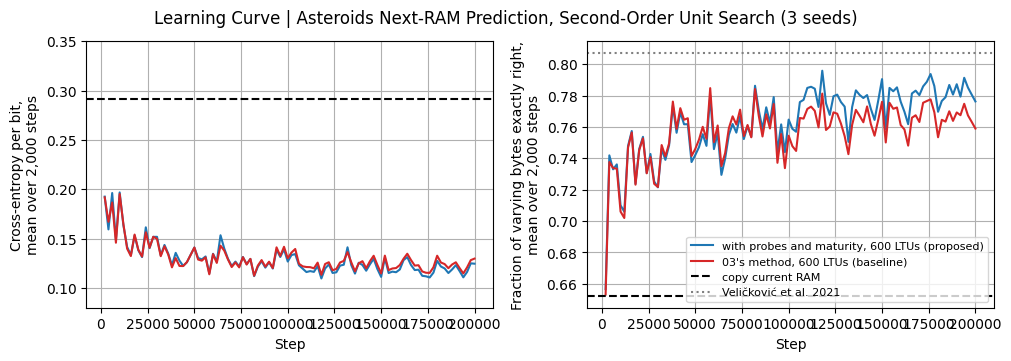

In [ ]:
steps = LOG_EVERY * np.arange(1, N_STEPS // LOG_EVERY + 1)   # end of each average
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
names = ['Cross-entropy per bit', 'Fraction of varying bytes exactly right']
METHODS = {f'with probes and maturity, {WIDTH} LTUs (proposed)': (CHANGED, 'tab:blue'),
           f'03\'s method, {WIDTH} LTUs (baseline)': (BASELINE, 'tab:red')}
for label, (config, color) in METHODS.items():
    for ax, values in zip(axes, scores[config].mean(0).T):
        ax.plot(steps, values, color=color, label=label)
for ax, ref, name in zip(axes, copy_final, names):
    ax.axhline(ref, color='k', ls='--', label='copy current RAM')
    ax.set(xlabel='Step', ylabel=f'{name},\nmean over {LOG_EVERY:,} steps')
    ax.grid()
axes[0].set_ylim(0.08, 0.35)
axes[1].axhline(RMR_ACCURACY, color='gray', ls=':', label='Veličković et al. 2021')
axes[1].legend(fontsize=8)
fig.suptitle(f'Learning Curve | Asteroids Next-RAM Prediction, Second-Order Unit Search ({N_SEEDS} seeds)')